<a href="https://colab.research.google.com/github/asiddiqha/waste-classification-cnn/blob/main/waste_classification_cnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Waste Material Classification with a CNN

**Author:** Ayesha · [GitHub](https://github.com/asiddiqha)

A convolutional neural network that sorts photos of waste into 7 material classes, to support automated recycling. Built with TensorFlow/Keras and trained on a Colab T4 GPU.

**Result:** 65.7% test accuracy and 0.65 macro F1 on 7 imbalanced classes, with a 3-block CNN trained from scratch.

## Why this matters

Manual waste sorting is slow, costly and error-prone, and badly sorted waste ends up in landfill instead of being recycled. An image classifier can help smart bins and sorting lines separate materials automatically.

Goals of this project:
* Classify waste images into 7 material types.
* Understand which materials are easy or hard to tell apart from a photo.
* Find out what helps or hurts the model: model size, dropout, learning rate and data augmentation.

## Dataset

7,625 images of common waste in 7 classes: Cardboard, Food Waste, Glass, Metal, Other, Paper and Plastic.

* Each class is a folder of images, and the folder name is the label.
* Items inside a class are not labelled further. For example, `Food_Waste` contains coffee grounds, tea bags and fruit peels, all under one label.

## 1. Load the data

**Libraries**

In [ ]:
# Recommended versions:

# numpy version: 1.26.4
# pandas version: 2.2.2
# seaborn version: 0.13.2
# matplotlib version: 3.10.0
# PIL version: 11.1.0
# tensorflow version: 2.18.0
# keras version: 3.8.0
# sklearn version: 1.6.1

In [ ]:
# Import essential libraries
import os
import zipfile
import random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
ImageFile.LOAD_TRUNCATED_IMAGES = True

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
NumPy: 2.4.6
Pandas: 2.2.3
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


**Getting the data:** Place the dataset ZIP (one folder per class) in the working folder, or set `DATASET_ZIP` to its path. A similar public waste-classification dataset is available on Kaggle. The dataset is not included in this repo.

In [ ]:
# Load and unzip the dataset
# Put the dataset ZIP in the working folder (on Colab: /content), or set DATASET_ZIP.
# If the ZIP is in Google Drive, set USE_GOOGLE_DRIVE = True and give its full path.
USE_GOOGLE_DRIVE = False
DATASET_ZIP = None   # e.g. "/content/drive/MyDrive/data.zip"
EXTRACT_DIR = Path("/content/waste_dataset") if Path("/content").exists() else Path("waste_dataset")

if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")

def find_zip_file():
    """Return the dataset ZIP: the path given in DATASET_ZIP, else the first ZIP in the working folder."""
    if DATASET_ZIP:
        return Path(DATASET_ZIP)
    for folder in [Path.cwd(), Path("/content")]:
        zips = sorted(folder.glob("*.zip")) if folder.exists() else []
        if zips:
            return zips[0]
    return None

zip_path = find_zip_file()
if EXTRACT_DIR.exists() and any(EXTRACT_DIR.iterdir()):
    print(f"Dataset already extracted at {EXTRACT_DIR.resolve()}")
elif zip_path is not None and zip_path.exists():
    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path, "r") as archive:
        archive.extractall(EXTRACT_DIR)
    print(f"Extracted {zip_path.name} to {EXTRACT_DIR.resolve()}")
else:
    raise FileNotFoundError(
        "Dataset ZIP not found. Upload it to /content (Files panel), or set "
        "USE_GOOGLE_DRIVE = True and DATASET_ZIP to its full path in Drive, then re-run this cell."
    )

Dataset already extracted at /content/waste_dataset


## 2. Data Preparation

### 2.1 Load and check the images

#### 2.1.1 Image loading function

In [ ]:
# Create a function to load the raw images
SUPPORTED_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def is_valid_image_file(path):
    """Skip macOS metadata files (._name, __MACOSX) and unsupported extensions."""
    return (path.suffix.lower() in SUPPORTED_EXTENSIONS
            and not path.name.startswith(".")
            and "__MACOSX" not in path.parts)

def load_images_from_folders(dataset_root, image_size=None):
    """Read images from class-named subfolders.

    Returns images (list of RGB uint8 arrays), labels (folder names), file paths
    and the number of unreadable files that were skipped.
    """
    dataset_root = Path(dataset_root)
    images, labels, image_paths = [], [], []
    skipped = 0

    class_dirs = sorted(p for p in dataset_root.iterdir()
                        if p.is_dir() and not p.name.startswith((".", "__")))
    for class_dir in class_dirs:
        for image_path in sorted(class_dir.rglob("*")):
            if not is_valid_image_file(image_path):
                continue
            try:
                with Image.open(image_path) as img:
                    img = img.convert("RGB")   # handles RGBA / grayscale / palette images
                    if image_size is not None:
                        img = img.resize(image_size, Image.Resampling.LANCZOS)
                    images.append(np.asarray(img, dtype=np.uint8))
                labels.append(class_dir.name)
                image_paths.append(str(image_path))
            except (OSError, ValueError):
                skipped += 1

    return images, np.asarray(labels), np.asarray(image_paths), skipped

#### 2.1.2 Load images and labels

I load every image from its class folder and check that each label matches its folder.

In [ ]:
# Get the images and their labels
# Locate the folder that holds the seven class subfolders (the ZIP may add an extra
# parent folder). Google Drive, Colab sample data and __MACOSX are skipped so the
# search stays fast and never picks the macOS metadata copy of the folders.
EXPECTED_CLASSES = {"Food_Waste", "Metal", "Paper", "Plastic", "Other", "Cardboard", "Glass"}
SKIP_DIRS = {"__MACOSX", "drive", "sample_data", ".config", ".ipynb_checkpoints"}

def find_dataset_root(search_roots, max_depth=4):
    expected = {name.lower() for name in EXPECTED_CLASSES}
    for root in map(Path, search_roots):
        if not root.exists():
            continue
        for dirpath, dirnames, _ in os.walk(root):
            dirnames[:] = [d for d in dirnames if d not in SKIP_DIRS and not d.startswith(".")]
            if len(expected & {d.lower() for d in dirnames}) >= 5:
                return Path(dirpath)
            if len(Path(dirpath).relative_to(root).parts) >= max_depth:
                dirnames[:] = []
    return None

DATASET_ROOT = find_dataset_root([EXTRACT_DIR, Path("/content"), Path.cwd()])
if DATASET_ROOT is None:
    raise FileNotFoundError(
        "Class folders not found. Check the ZIP was extracted in the previous cell."
    )

images_raw, labels, image_paths, skipped_files = load_images_from_folders(DATASET_ROOT)
print("Dataset directory:", DATASET_ROOT.resolve())
print("Images loaded:", len(images_raw))
print("Classes found:", sorted(set(labels.tolist())))
print("Unreadable images skipped:", skipped_files)

if len(images_raw) == 0:
    raise ValueError("No supported image files were found in the class folders.")

# Verify that labels match the parent folder of each image
assert all(Path(p).relative_to(DATASET_ROOT).parts[0] == lab for p, lab in zip(image_paths, labels))
print("Label check passed: every label matches its folder name.")
print("Sample (label, file):", list(zip(labels[:3].tolist(), [Path(p).name for p in image_paths[:3]])))

Dataset directory: /content/waste_dataset/Dataset_Waste_Segregation/Dataset_Waste_Segregation/data
Images loaded: 7625
Classes found: ['Cardboard', 'Food_Waste', 'Glass', 'Metal', 'Other', 'Paper', 'Plastic']
Unreadable images skipped: 0
Label check passed: every label matches its folder name.
Sample (label, file): [('Cardboard', 'file_1.png'), ('Cardboard', 'file_10.png'), ('Cardboard', 'file_100.png')]


In [ ]:
# Data quality check: exact duplicate images (same file content), possibly across classes
import hashlib

file_hashes = pd.Series([hashlib.md5(Path(p).read_bytes()).hexdigest() for p in image_paths])
dup_mask = file_hashes.duplicated(keep=False)
print("Images that have an exact duplicate:", int(dup_mask.sum()))

dup_groups = pd.DataFrame({"hash": file_hashes, "label": labels})[dup_mask].groupby("hash")["label"].nunique()
print("Duplicate groups with conflicting labels:", int((dup_groups > 1).sum()))

Images that have an exact duplicate: 985
Duplicate groups with conflicting labels: 9


**What I found while loading:** All 7,625 images loaded fine and none were corrupt, so nothing was skipped. I took the label of each image from its folder name and checked that every label matches its folder.

While checking quality, I found 985 images that have an exact copy somewhere in the dataset. In 9 cases the same image is saved in two different class folders, so it has two different labels. I kept these images because there are not many of them, but I have noted it as a data quality issue. Some copies can end up in both the training and test sets, which can make the test score look a little better than it really is.

### 2.2 Data Visualisation

#### 2.2.1 Class distribution

,Class,Image count
0,Cardboard,540
1,Food_Waste,1000
2,Glass,750
3,Metal,1000
4,Other,1010
5,Paper,1030
6,Plastic,2295


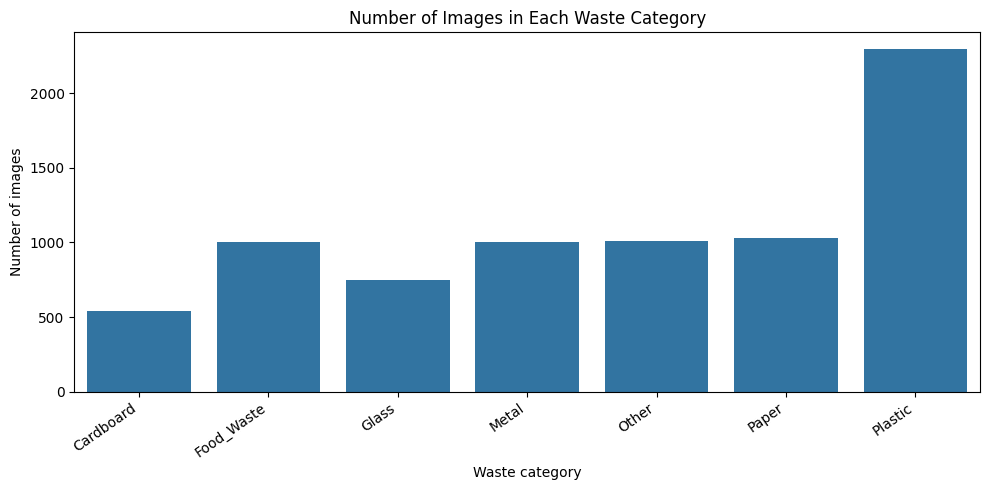

Total images: 7625
Number of classes: 7
Largest class: Plastic - 2295
Smallest class: Cardboard - 540
Class imbalance ratio (largest/smallest): 4.25


In [ ]:
# Visualise Data Distribution
class_counts = pd.Series(labels).value_counts().sort_index()
distribution_df = class_counts.rename_axis("Class").reset_index(name="Image count")
display(distribution_df)

plt.figure(figsize=(10, 5))
sns.barplot(data=distribution_df, x="Class", y="Image count")
plt.title("Number of Images in Each Waste Category")
plt.xlabel("Waste category")
plt.ylabel("Number of images")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

print("Total images:", len(labels))
print("Number of classes:", len(class_counts))
print("Largest class:", class_counts.idxmax(), "-", class_counts.max())
print("Smallest class:", class_counts.idxmin(), "-", class_counts.min())
print("Class imbalance ratio (largest/smallest):", round(class_counts.max() / class_counts.min(), 2))

**My observation:** The classes are not balanced. Plastic is the biggest class with 2,295 images, which is about 30% of the data. Cardboard is the smallest with only 540 images. Plastic has about 4.25 times more images than Cardboard. The other classes are close to each other, between 750 (Glass) and 1,030 (Paper).

If I train without fixing this, the model can learn to guess "Plastic" too often, because that guess is right most of the time. So I used a stratified split and class weights during training. The class weights make a mistake on a rare class (like Cardboard, weight 2.02) cost more than a mistake on Plastic (weight 0.47).

#### 2.2.2 Sample images

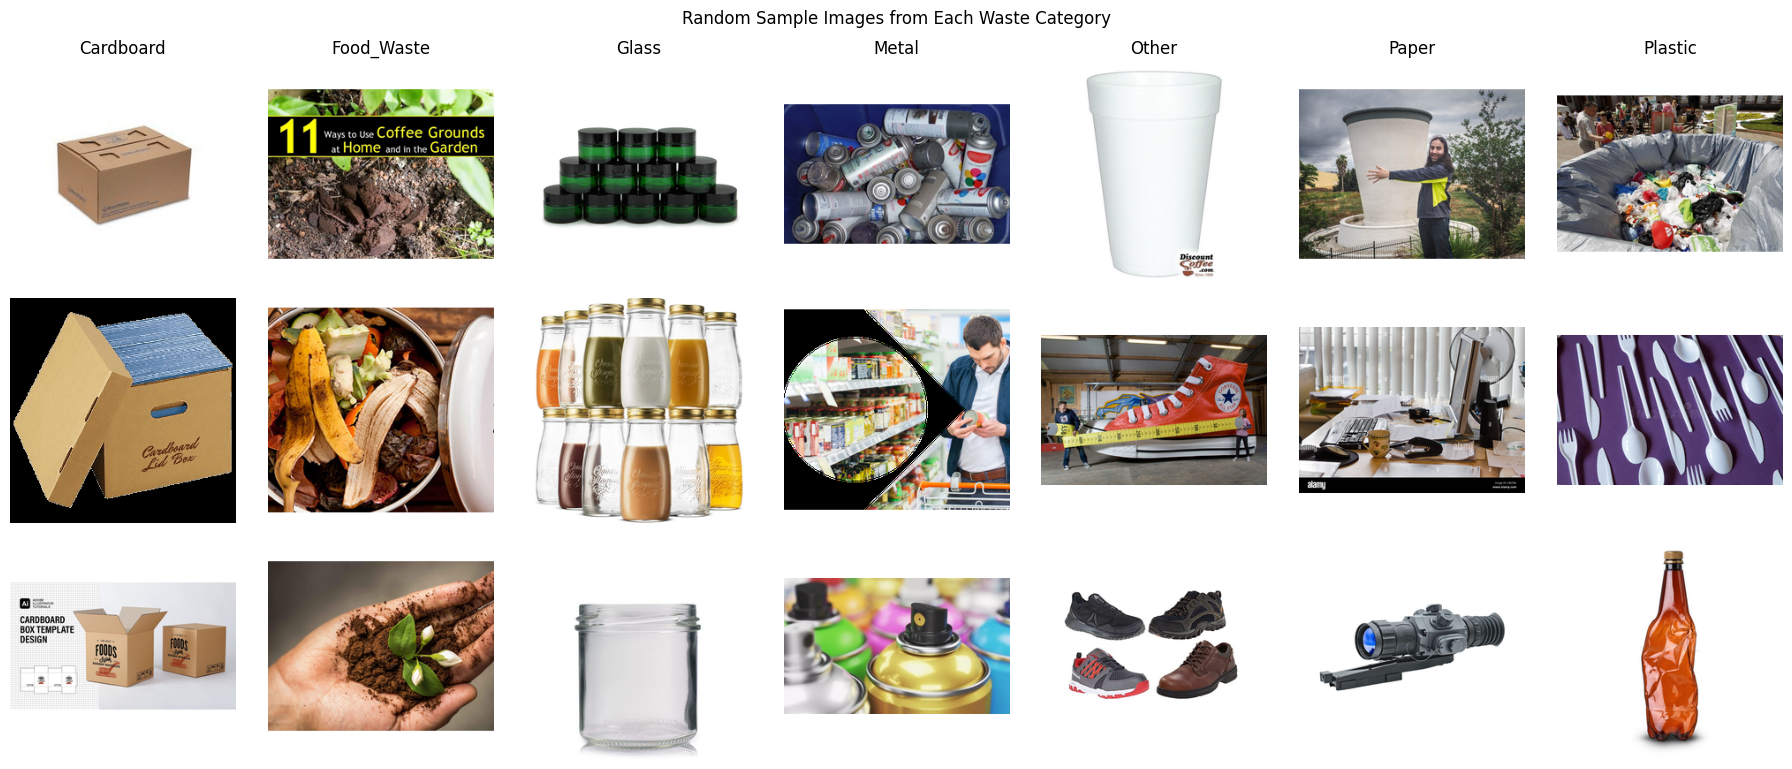

In [ ]:
# Visualise Sample Images (across different labels)
class_names_present = sorted(np.unique(labels))
SAMPLES_PER_CLASS = 3
rng = np.random.default_rng(SEED)

fig, axes = plt.subplots(SAMPLES_PER_CLASS, len(class_names_present),
                         figsize=(2.6 * len(class_names_present), 2.6 * SAMPLES_PER_CLASS))
for col, class_name in enumerate(class_names_present):
    picks = rng.choice(np.where(labels == class_name)[0], SAMPLES_PER_CLASS, replace=False)
    for row, sample_idx in enumerate(picks):
        ax = axes[row, col]
        ax.imshow(images_raw[sample_idx])
        ax.axis("off")
        if row == 0:
            ax.set_title(class_name)
plt.suptitle("Random Sample Images from Each Waste Category")
plt.tight_layout()
plt.show()

#### 2.2.3 Image sizes and resizing

In [ ]:
# Find the smallest and largest image dimensions from the data set
dims = pd.DataFrame([img.shape[:2] for img in images_raw], columns=["height", "width"])
dims["area"] = dims["height"] * dims["width"]

print(f"Width range : {dims.width.min()} to {dims.width.max()} pixels")
print(f"Height range: {dims.height.min()} to {dims.height.max()} pixels")
print("Smallest image (h x w):", tuple(dims.loc[dims.area.idxmin(), ["height", "width"]]))
print("Largest image  (h x w):", tuple(dims.loc[dims.area.idxmax(), ["height", "width"]]))
print("Number of distinct image sizes:", len(dims.groupby(["height", "width"])))
print("Most common sizes:\n", dims.value_counts(["height", "width"]).head())

# The CNN needs one fixed input shape. 128x128 is not larger than the smallest
# common image size, so no image is enlarged much, and it keeps memory/training time low.
IMG_SIZE = (128, 128)

Width range : 256 to 256 pixels
Height range: 256 to 256 pixels
Smallest image (h x w): (256, 256)
Largest image  (h x w): (256, 256)
Number of distinct image sizes: 1
Most common sizes:
 height  width
256     256      7625
Name: count, dtype: int64


In [ ]:
# Resize the image dimensions
X = np.stack([
    np.asarray(Image.fromarray(img).resize(IMG_SIZE, Image.Resampling.LANCZOS), dtype=np.uint8)
    for img in images_raw
])
print("Resized image array shape:", X.shape)

# Scale pixel values to [0, 1] for stable training
X = X.astype("float32") / 255.0
print("Normalised pixel range:", X.min(), "to", X.max())

# Free the original-size images (no longer needed) to save RAM on Colab
import gc
del images_raw
gc.collect()

Resized image array shape: (7625, 128, 128, 3)
Normalised pixel range: 0.0 to 1.0


133

**My observation:** Every image in this dataset is already 256 x 256 pixels, so the smallest and largest sizes are the same and there are no size outliers. I still resized all images to 128 x 128. This makes the data 4 times smaller in memory and training much faster on the Colab GPU, and the objects are still easy to recognise at this size. I also scaled the pixel values from 0–255 to 0–1, because the network trains more smoothly with small input values.

### 2.3 Label encoding

There are 7 classes. I convert the class names to integers (and later to one-hot vectors for the loss function).

In [ ]:
# Encode the labels suitably
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(labels)
class_names = label_encoder.classes_.tolist()
NUM_CLASSES = len(class_names)

print("Class-to-index mapping:")
for index, class_name in enumerate(class_names):
    print(f"{class_name}: {index}")
print("Encoded labels shape:", y.shape)

Class-to-index mapping:
Cardboard: 0
Food_Waste: 1
Glass: 2
Metal: 3
Other: 4
Paper: 5
Plastic: 6
Encoded labels shape: (7625,)


### 2.4 Train / validation / test split

In [ ]:
# Assign specified parts of the dataset to train and validation sets
# 70% train / 15% validation / 15% test, stratified so every split keeps the class ratio.
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)
del X, X_temp   # free memory; the three splits hold all the data now
gc.collect()

print("Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Test set:", X_test.shape, y_test.shape)

# One-hot labels for categorical cross-entropy
y_train_cat = keras.utils.to_categorical(y_train, NUM_CLASSES)
y_val_cat = keras.utils.to_categorical(y_val, NUM_CLASSES)
y_test_cat = keras.utils.to_categorical(y_test, NUM_CLASSES)

# Class weights to reduce the effect of class imbalance during training
from sklearn.utils.class_weight import compute_class_weight
weights = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_train)
CLASS_WEIGHTS = dict(enumerate(weights))
print("Class weights:", {class_names[k]: round(v, 2) for k, v in CLASS_WEIGHTS.items()})

Training set: (5337, 128, 128, 3) (5337,)
Validation set: (1144, 128, 128, 3) (1144,)
Test set: (1144, 128, 128, 3) (1144,)
Class weights: {'Cardboard': np.float64(2.02), 'Food_Waste': np.float64(1.09), 'Glass': np.float64(1.45), 'Metal': np.float64(1.09), 'Other': np.float64(1.08), 'Paper': np.float64(1.06), 'Plastic': np.float64(0.47)}


**My observation:** I split the data into 70% training (5,337 images), 15% validation (1,144) and 15% test (1,144). I used a stratified split, so each part keeps the same class ratio as the full dataset. I use the validation set to choose the best model and the test set only once, at the end, so the final score is on images the model has never seen.

## 3. Model Building and Evaluation

### 3.1 Building and training the CNN

#### 3.1.1 Model architecture

Each model has 3 convolution blocks (Conv2D → BatchNormalization → MaxPooling), then global average pooling, a Dense layer, Dropout and a softmax output. I compare three configurations that differ in filter count, dropout and learning rate.

In [ ]:
# Build and compile the model
def build_cnn_model(input_shape=(128, 128, 3), num_classes=7,
                    filters=(32, 64, 128), dropout_rate=0.40,
                    learning_rate=1e-3, dense_units=128):
    """CNN with three Conv blocks (Conv -> BatchNorm -> MaxPool), then a dense head."""
    model = keras.Sequential([layers.Input(shape=input_shape)])
    for n_filters in filters:
        model.add(layers.Conv2D(n_filters, (3, 3), padding="same", activation="relu"))
        model.add(layers.BatchNormalization())
        model.add(layers.MaxPooling2D((2, 2)))

    model.add(layers.GlobalAveragePooling2D())
    model.add(layers.Dense(dense_units, activation="relu"))
    model.add(layers.Dropout(dropout_rate))
    model.add(layers.Dense(num_classes, activation="softmax"))

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="categorical_crossentropy",   # multi-class with one-hot labels
        metrics=["accuracy"]
    )
    return model

# Configurations to compare (all use the required 3 convolutional layers)
CONFIGS = {
    "A: 32-64-128, dropout 0.4, lr 1e-3": dict(filters=(32, 64, 128), dropout_rate=0.4, learning_rate=1e-3),
    "B: 64-128-256, dropout 0.5, lr 1e-3": dict(filters=(64, 128, 256), dropout_rate=0.5, learning_rate=1e-3),
    "C: 32-64-128, dropout 0.3, lr 5e-4": dict(filters=(32, 64, 128), dropout_rate=0.3, learning_rate=5e-4),
}

build_cnn_model(input_shape=(*IMG_SIZE, 3), num_classes=NUM_CLASSES, **CONFIGS[list(CONFIGS)[0]]).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,559 (435.78 KB)

 Trainable params: 111,111 (434.03 KB)

 Non-trainable params: 448 (1.75 KB)

#### 3.1.2 Training

Training uses early stopping (on validation loss, with at least 10 epochs) and lowers the learning rate when validation loss stops improving. Class weights balance the classes.


===== Training configuration A: 32-64-128, dropout 0.4, lr 1e-3 =====
Epoch 1/25
167/167 - 37s - 220ms/step - accuracy: 0.3032 - loss: 1.7392 - val_accuracy: 0.1425 - val_loss: 2.1245 - learning_rate: 0.0010
Epoch 2/25
167/167 - 4s - 23ms/step - accuracy: 0.3828 - loss: 1.5846 - val_accuracy: 0.1582 - val_loss: 2.1092 - learning_rate: 0.0010
Epoch 3/25
167/167 - 4s - 24ms/step - accuracy: 0.4190 - loss: 1.5024 - val_accuracy: 0.3698 - val_loss: 1.6518 - learning_rate: 0.0010
Epoch 4/25
167/167 - 4s - 23ms/step - accuracy: 0.4373 - loss: 1.4434 - val_accuracy: 0.4432 - val_loss: 1.4987 - learning_rate: 0.0010
Epoch 5/25
167/167 - 4s - 23ms/step - accuracy: 0.4694 - loss: 1.3865 - val_accuracy: 0.3855 - val_loss: 1.7384 - learning_rate: 0.0010
Epoch 6/25

Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
167/167 - 4s - 25ms/step - accuracy: 0.4917 - loss: 1.3208 - val_accuracy: 0.3733 - val_loss: 1.9060 - learning_rate: 0.0010
Epoch 7/25
167/167 - 4s - 24ms/ste

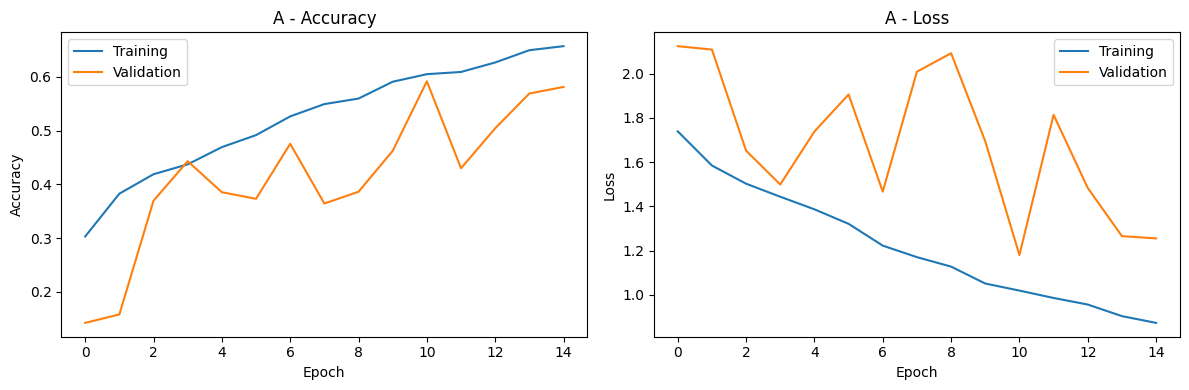


===== Training configuration B: 64-128-256, dropout 0.5, lr 1e-3 =====
Epoch 1/25
167/167 - 38s - 225ms/step - accuracy: 0.2912 - loss: 1.8050 - val_accuracy: 0.1093 - val_loss: 2.7307 - learning_rate: 0.0010
Epoch 2/25
167/167 - 7s - 45ms/step - accuracy: 0.3470 - loss: 1.6434 - val_accuracy: 0.1399 - val_loss: 2.8715 - learning_rate: 0.0010
Epoch 3/25
167/167 - 8s - 45ms/step - accuracy: 0.3937 - loss: 1.5660 - val_accuracy: 0.2247 - val_loss: 2.2760 - learning_rate: 0.0010
Epoch 4/25
167/167 - 8s - 45ms/step - accuracy: 0.4051 - loss: 1.5298 - val_accuracy: 0.3916 - val_loss: 1.7310 - learning_rate: 0.0010
Epoch 5/25
167/167 - 8s - 46ms/step - accuracy: 0.4334 - loss: 1.4733 - val_accuracy: 0.3960 - val_loss: 1.7723 - learning_rate: 0.0010
Epoch 6/25

Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
167/167 - 10s - 61ms/step - accuracy: 0.4523 - loss: 1.4149 - val_accuracy: 0.2552 - val_loss: 2.2789 - learning_rate: 0.0010
Epoch 7/25
167/167 - 7s - 45ms/s

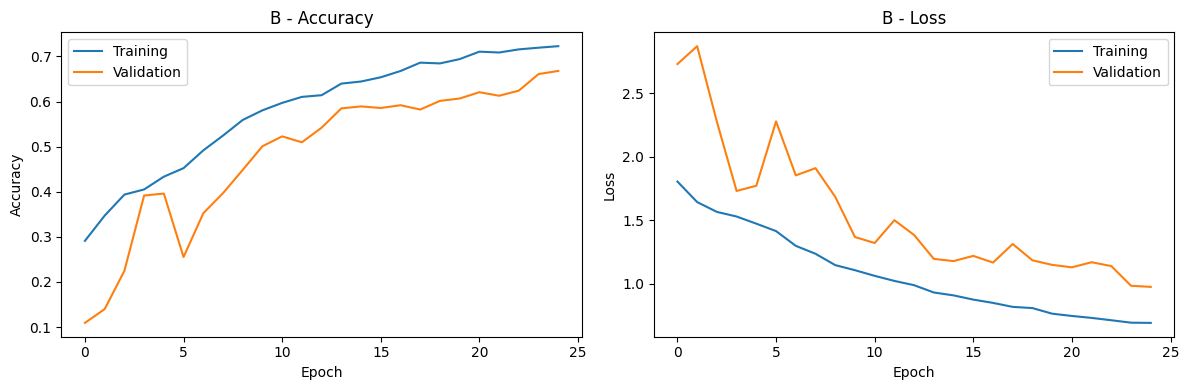


===== Training configuration C: 32-64-128, dropout 0.3, lr 5e-4 =====
Epoch 1/25
167/167 - 16s - 96ms/step - accuracy: 0.3352 - loss: 1.6932 - val_accuracy: 0.1294 - val_loss: 2.0168 - learning_rate: 5.0000e-04
Epoch 2/25
167/167 - 4s - 24ms/step - accuracy: 0.4012 - loss: 1.5355 - val_accuracy: 0.1399 - val_loss: 2.2032 - learning_rate: 5.0000e-04
Epoch 3/25
167/167 - 4s - 23ms/step - accuracy: 0.4345 - loss: 1.4592 - val_accuracy: 0.2587 - val_loss: 1.7543 - learning_rate: 5.0000e-04
Epoch 4/25
167/167 - 4s - 25ms/step - accuracy: 0.4658 - loss: 1.3977 - val_accuracy: 0.4117 - val_loss: 1.5474 - learning_rate: 5.0000e-04
Epoch 5/25
167/167 - 4s - 25ms/step - accuracy: 0.4904 - loss: 1.3460 - val_accuracy: 0.5122 - val_loss: 1.3764 - learning_rate: 5.0000e-04
Epoch 6/25
167/167 - 4s - 24ms/step - accuracy: 0.5059 - loss: 1.3026 - val_accuracy: 0.4510 - val_loss: 1.4397 - learning_rate: 5.0000e-04
Epoch 7/25

Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.


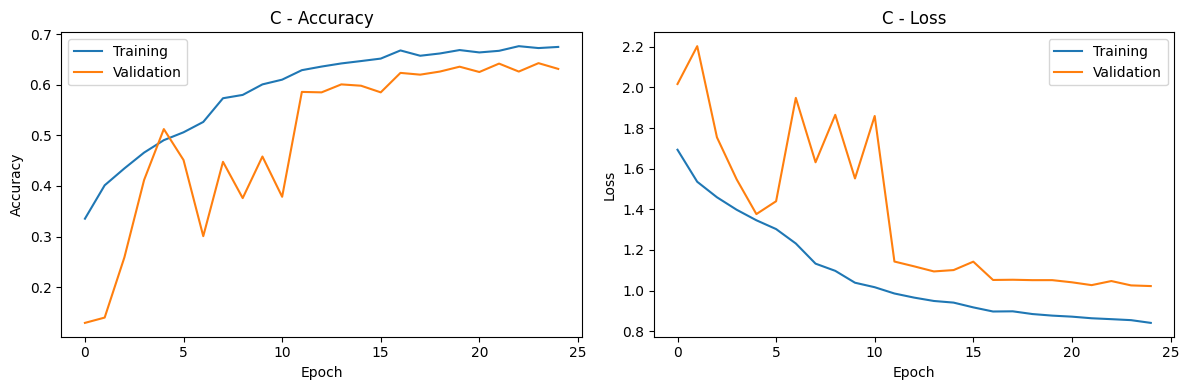

,Configuration,Epochs run,Best epoch,Train acc (best epoch),Val acc (best epoch),Val loss (best epoch)
0,"A: 32-64-128, dropout 0.4, lr 1e-3",15,11,0.6050,0.5918,1.1797
1,"B: 64-128-256, dropout 0.5, lr 1e-3",25,25,0.7227,0.6678,0.9755
2,"C: 32-64-128, dropout 0.3, lr 5e-4",25,25,0.6745,0.6311,1.0221


Selected configuration: B: 64-128-256, dropout 0.5, lr 1e-3


In [ ]:
# Training
BATCH_SIZE = 32
EPOCHS = 25   # upper limit; early stopping cannot stop before epoch 10 (so every run trains for at least 10 epochs)

def make_callbacks():
    """New callback objects for every run (callbacks keep internal state)."""
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, start_from_epoch=10,
                                      restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2,
                                          min_lr=1e-6, verbose=1),
    ]

def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metric in zip(axes, ["accuracy", "loss"]):
        ax.plot(history.history[metric], label="Training")
        ax.plot(history.history[f"val_{metric}"], label="Validation")
        ax.set_title(f"{title} - {metric.capitalize()}")
        ax.set_xlabel("Epoch")
        ax.set_ylabel(metric.capitalize())
        ax.legend()
    plt.tight_layout()
    plt.show()

results, trained = [], {}
for name, params in CONFIGS.items():
    print(f"\n===== Training configuration {name} =====")
    keras.backend.clear_session()
    tf.random.set_seed(SEED)
    cfg_model = build_cnn_model(input_shape=(*IMG_SIZE, 3), num_classes=NUM_CLASSES, **params)
    cfg_history = cfg_model.fit(
        X_train, y_train_cat,
        validation_data=(X_val, y_val_cat),
        epochs=EPOCHS, batch_size=BATCH_SIZE,
        class_weight=CLASS_WEIGHTS,
        callbacks=make_callbacks(), verbose=2
    )
    best_epoch = int(np.argmin(cfg_history.history["val_loss"]))
    results.append({
        "Configuration": name,
        "Epochs run": len(cfg_history.history["loss"]),
        "Best epoch": best_epoch + 1,
        "Train acc (best epoch)": cfg_history.history["accuracy"][best_epoch],
        "Val acc (best epoch)": cfg_history.history["val_accuracy"][best_epoch],
        "Val loss (best epoch)": cfg_history.history["val_loss"][best_epoch],
    })
    trained[name] = (cfg_model, cfg_history)
    plot_history(cfg_history, name.split(":")[0])

config_results = pd.DataFrame(results).round(4)
display(config_results)

# Select the configuration with the lowest validation loss (test set is NOT used for selection)
BEST_CONFIG = config_results.loc[config_results["Val loss (best epoch)"].idxmin(), "Configuration"]
model, history = trained[BEST_CONFIG]
print("Selected configuration:", BEST_CONFIG)

**My observation on the three configurations:**

| Config | Filters | Dropout | Learning rate | Best val accuracy | Best val loss |
|---|---|---|---|---|---|
| A | 32-64-128 | 0.4 | 0.001 | 0.592 | 1.180 |
| B | 64-128-256 | 0.5 | 0.001 | **0.668** | **0.976** |
| C | 32-64-128 | 0.3 | 0.0005 | 0.631 | 1.022 |

Config B worked best, so I selected it. It has more filters in each layer, so it can learn more patterns like texture, shine and edges. The higher dropout (0.5) helped keep it from memorising the training images.

Config A stopped early at epoch 15 because its validation loss stopped improving after epoch 11. Configs B and C used all 25 epochs, and their best epoch was the last one. This tells me they were still improving, so training for more epochs would probably give a better score.

The gap between training and validation accuracy for B is small (0.72 vs 0.67, about 5%). So the model is not overfitting much. If anything, it is still a bit underfitting, which again points to more epochs or a bigger model.

### 3.2 Test-set evaluation

Selected model: B: 64-128-256, dropout 0.5, lr 1e-3
Test loss: 0.9889
Test accuracy: 0.6573

Classification report:
              precision    recall  f1-score   support

   Cardboard       0.76      0.79      0.78        81
  Food_Waste       0.70      0.77      0.73       150
       Glass       0.62      0.61      0.61       113
       Metal       0.66      0.74      0.70       150
       Other       0.56      0.54      0.55       151
       Paper       0.67      0.41      0.51       155
     Plastic       0.66      0.72      0.69       344

    accuracy                           0.66      1144
   macro avg       0.66      0.65      0.65      1144
weighted avg       0.66      0.66      0.65      1144



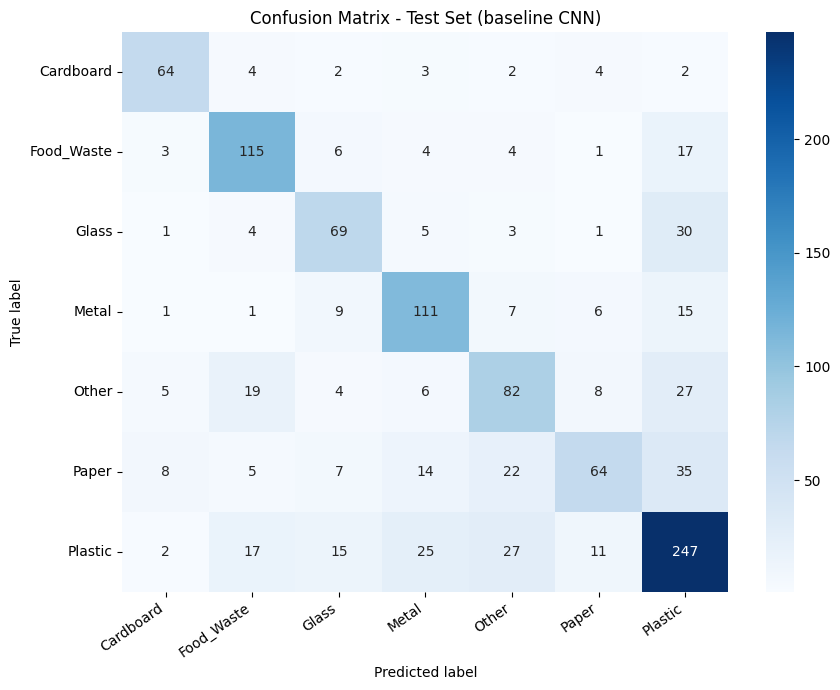

In [ ]:
# Evaluate on the test set; display suitable metrics
test_loss, test_accuracy = model.evaluate(X_test, y_test_cat, verbose=0)
y_prob = model.predict(X_test, batch_size=BATCH_SIZE, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print(f"Selected model: {BEST_CONFIG}")
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, labels=np.arange(NUM_CLASSES),
                            target_names=class_names, zero_division=0))

def plot_confusion(y_true, y_hat, title):
    cm = confusion_matrix(y_true, y_hat, labels=np.arange(NUM_CLASSES))
    plt.figure(figsize=(9, 7))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.title(title)
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.xticks(rotation=35, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()
    return cm

cm = plot_confusion(y_test, y_pred, "Confusion Matrix - Test Set (baseline CNN)")

**My observation on the test results:** On the test set, my model got **65.7% accuracy**, a test loss of 0.989 and a macro F1-score of 0.65. These are very close to the validation results, so the model behaves the same on new images.

Class by class:
- **Cardboard** is the best class (F1 0.78). Even though it is the smallest class, its brown colour and flat surface are easy to spot, and the class weight helped.
- **Food Waste** (0.73), **Metal** (0.70) and **Plastic** (0.69) are also reasonably good.
- **Glass** (0.61) and **Other** (0.55) are weaker.
- **Paper** is the weakest (F1 0.51). Its recall is only 0.41, which means the model misses more than half of the paper images.

From the confusion matrix, the biggest mistakes are:
- Paper predicted as Plastic (35 images)
- Glass predicted as Plastic (30 images)
- Plastic predicted as Other (27 images)

These mistakes make sense to me. A plastic bottle and a glass bottle look very alike, and shiny or printed paper can look like plastic wrapping. "Other" is a mixed class with no single look, so it overlaps with everything. Many errors go towards Plastic because it is the biggest class, even with the class weights.

## 4. Data Augmentation

### 4.1 Augmentation pipeline

#### 4.1.1 Augmentation steps

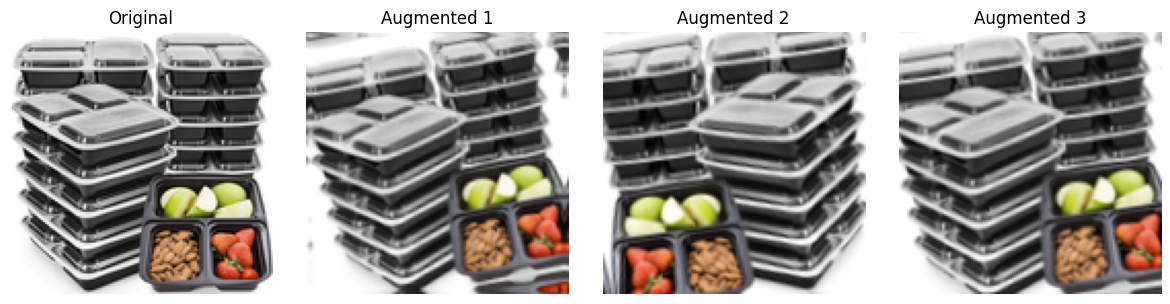

In [ ]:
# Define augmentation steps to augment images
# Augmentation is applied only to training images, never to validation/test images.
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10)
], name="data_augmentation")

# Preview: original image followed by three random augmented versions
sample_batch = tf.expand_dims(X_train[0], axis=0)
preview = [sample_batch[0]] + [data_augmentation(sample_batch, training=True)[0] for _ in range(3)]
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, image, title in zip(axes, preview, ["Original", "Augmented 1", "Augmented 2", "Augmented 3"]):
    ax.imshow(tf.clip_by_value(image, 0, 1))
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

Random flips, small rotations, zoom and contrast changes are applied on the fly to training images only, never to validation or test images.

In [ ]:
# Create a function to augment the images
def make_augmented_dataset(images, labels, batch_size=32, shuffle=True):
    """tf.data pipeline that augments training images on the fly (new variations every epoch)."""
    dataset = tf.data.Dataset.from_tensor_slices((images, labels))
    if shuffle:
        dataset = dataset.shuffle(buffer_size=min(len(images), 2000), seed=SEED,
                                  reshuffle_each_iteration=True)
    dataset = dataset.batch(batch_size)
    dataset = dataset.map(
        lambda image_batch, label_batch: (
            tf.clip_by_value(data_augmentation(image_batch, training=True), 0.0, 1.0), label_batch
        ),
        num_parallel_calls=tf.data.AUTOTUNE
    )
    return dataset.prefetch(tf.data.AUTOTUNE)

In [ ]:
# Create the augmented training dataset
train_aug_ds = make_augmented_dataset(X_train, y_train_cat, BATCH_SIZE, shuffle=True)
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val_cat)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test_cat)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Augmented training batches:", tf.data.experimental.cardinality(train_aug_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())

Augmented training batches: 167
Validation batches: 36
Test batches: 36


#### 4.1.2 Training with augmented images

Epoch 1/25
167/167 - 32s - 194ms/step - accuracy: 0.2985 - loss: 1.8051 - val_accuracy: 0.1189 - val_loss: 2.3857 - learning_rate: 0.0010
Epoch 2/25
167/167 - 19s - 114ms/step - accuracy: 0.3395 - loss: 1.6651 - val_accuracy: 0.1302 - val_loss: 2.3450 - learning_rate: 0.0010
Epoch 3/25
167/167 - 21s - 123ms/step - accuracy: 0.3613 - loss: 1.6373 - val_accuracy: 0.3706 - val_loss: 1.6258 - learning_rate: 0.0010
Epoch 4/25
167/167 - 19s - 114ms/step - accuracy: 0.3871 - loss: 1.5758 - val_accuracy: 0.3164 - val_loss: 1.9989 - learning_rate: 0.0010
Epoch 5/25

Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
167/167 - 22s - 130ms/step - accuracy: 0.3984 - loss: 1.5444 - val_accuracy: 0.3881 - val_loss: 1.6650 - learning_rate: 0.0010
Epoch 6/25
167/167 - 19s - 116ms/step - accuracy: 0.4287 - loss: 1.4654 - val_accuracy: 0.3339 - val_loss: 1.8099 - learning_rate: 5.0000e-04
Epoch 7/25
167/167 - 21s - 125ms/step - accuracy: 0.4471 - loss: 1.4211 - val_accuracy: 0.4

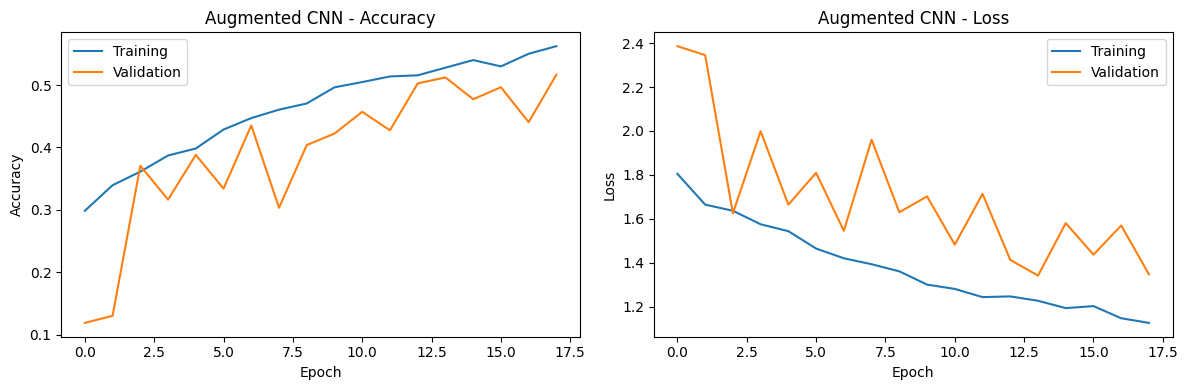

Augmented model test loss: 1.3503
Augmented model test accuracy: 0.5271
              precision    recall  f1-score   support

   Cardboard       0.69      0.81      0.75        81
  Food_Waste       0.68      0.59      0.63       150
       Glass       0.48      0.55      0.51       113
       Metal       0.36      0.71      0.48       150
       Other       0.49      0.29      0.37       151
       Paper       0.38      0.51      0.44       155
     Plastic       0.80      0.46      0.58       344

    accuracy                           0.53      1144
   macro avg       0.55      0.56      0.54      1144
weighted avg       0.59      0.53      0.53      1144



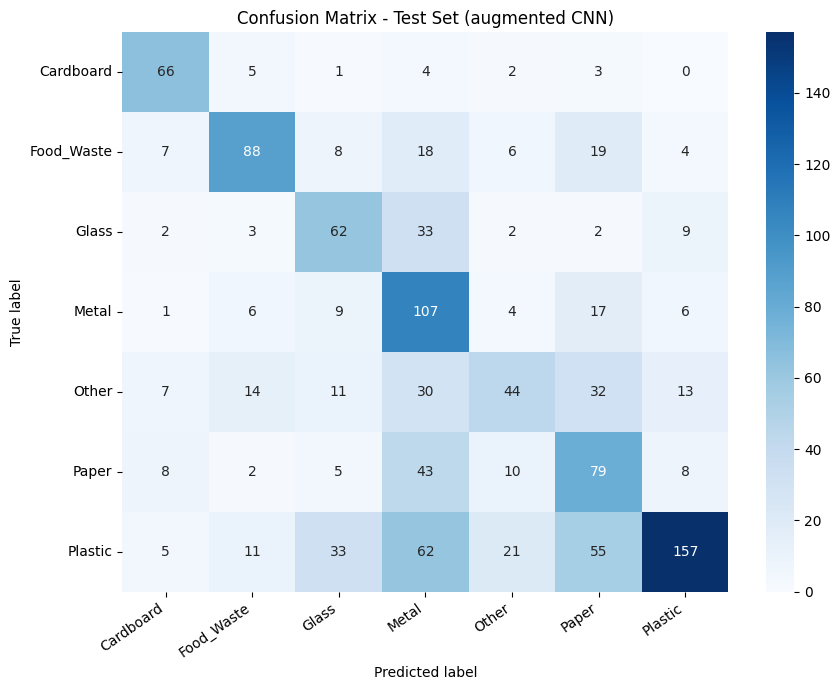

,Model,Test loss,Test accuracy,Macro F1
0,CNN without augmentation,0.9889,0.6573,0.6527
1,CNN with augmentation,1.3503,0.5271,0.5359


In [ ]:
# Train the model using augmented images (same best configuration, so only augmentation changes)
keras.backend.clear_session()
tf.random.set_seed(SEED)
augmented_model = build_cnn_model(input_shape=(*IMG_SIZE, 3), num_classes=NUM_CLASSES,
                                  **CONFIGS[BEST_CONFIG])

augmented_history = augmented_model.fit(
    train_aug_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=CLASS_WEIGHTS,
    callbacks=make_callbacks(),
    verbose=2
)
plot_history(augmented_history, "Augmented CNN")

aug_test_loss, aug_test_accuracy = augmented_model.evaluate(test_ds, verbose=0)
aug_pred = np.argmax(augmented_model.predict(test_ds, verbose=0), axis=1)
print(f"Augmented model test loss: {aug_test_loss:.4f}")
print(f"Augmented model test accuracy: {aug_test_accuracy:.4f}")
print(classification_report(y_test, aug_pred, labels=np.arange(NUM_CLASSES),
                            target_names=class_names, zero_division=0))
aug_cm = plot_confusion(y_test, aug_pred, "Confusion Matrix - Test Set (augmented CNN)")

# Compare both approaches on the same held-out test set
from sklearn.metrics import f1_score
comparison = pd.DataFrame({
    "Model": ["CNN without augmentation", "CNN with augmentation"],
    "Test loss": [test_loss, aug_test_loss],
    "Test accuracy": [test_accuracy, aug_test_accuracy],
    "Macro F1": [f1_score(y_test, y_pred, average="macro"), f1_score(y_test, aug_pred, average="macro")],
}).round(4)
display(comparison)

**My observation on augmentation:** I expected augmentation to help, but here it made the results worse:

| Model | Test accuracy | Test loss | Macro F1 |
|---|---|---|---|
| Without augmentation | **0.657** | **0.989** | **0.653** |
| With augmentation | 0.527 | 1.350 | 0.536 |

The training and validation curves of the augmented model are very close (gap only about 1.6%), so it is not overfitting. The problem is that it learned less. Flips, rotations, zoom and contrast changes make every training image a little different in each epoch, so the task is harder and the model needs more epochs to learn it. Early stopping ended training at epoch 18 (best weights from epoch 14), before the model could catch up.

The class report shows this too. Metal recall went up to 0.71, but its precision dropped to 0.36, so the model started calling many other items Metal. Plastic recall dropped from 0.72 to 0.46.

So for this dataset and this training time, augmentation did not improve generalisation. I think it would need longer training, a gentler set of augmentations or a slower learning rate drop before it helps.

## 5. Conclusions

In [ ]:
# Summary of the key numbers behind the conclusions
def train_val_gap(h):
    best = int(np.argmin(h.history["val_loss"]))
    return round(h.history["accuracy"][best] - h.history["val_accuracy"][best], 4)

def top_confusions(cm, k=3):
    off_diag = [(int(cm[i, j]), str(class_names[i]), str(class_names[j]))
                for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j]
    return sorted(off_diag, reverse=True)[:k]

print("Dataset size:", len(labels), "| Classes:", class_names)
print("Class counts:", class_counts.to_dict())
print("Skipped unreadable files:", skipped_files, "| Duplicate images:", int(dup_mask.sum()))
print("Image size used:", IMG_SIZE)
display(config_results)
print("Selected configuration:", BEST_CONFIG)
print(f"Baseline  test accuracy {test_accuracy:.4f} | loss {test_loss:.4f} | train-val gap {train_val_gap(history)}")
print(f"Augmented test accuracy {aug_test_accuracy:.4f} | loss {aug_test_loss:.4f} | train-val gap {train_val_gap(augmented_history)}")
print("Most confused (count, true -> predicted), baseline:", top_confusions(cm))

Dataset size: 7625 | Classes: ['Cardboard', 'Food_Waste', 'Glass', 'Metal', 'Other', 'Paper', 'Plastic']
Class counts: {'Cardboard': 540, 'Food_Waste': 1000, 'Glass': 750, 'Metal': 1000, 'Other': 1010, 'Paper': 1030, 'Plastic': 2295}
Skipped unreadable files: 0 | Duplicate images: 985
Image size used: (128, 128)


,Configuration,Epochs run,Best epoch,Train acc (best epoch),Val acc (best epoch),Val loss (best epoch)
0,"A: 32-64-128, dropout 0.4, lr 1e-3",15,11,0.6050,0.5918,1.1797
1,"B: 64-128-256, dropout 0.5, lr 1e-3",25,25,0.7227,0.6678,0.9755
2,"C: 32-64-128, dropout 0.3, lr 5e-4",25,25,0.6745,0.6311,1.0221


Selected configuration: B: 64-128-256, dropout 0.5, lr 1e-3
Baseline  test accuracy 0.6573 | loss 0.9889 | train-val gap 0.0549
Augmented test accuracy 0.5271 | loss 1.3503 | train-val gap 0.0156
Most confused (count, true -> predicted), baseline: [(35, 'Paper', 'Plastic'), (30, 'Glass', 'Plastic'), (27, 'Plastic', 'Other')]


### Key findings

**About the data.** The dataset has 7,625 images in 7 classes. It is imbalanced: Plastic has 2,295 images and Cardboard only 540, a ratio of about 4.25 to 1. I handled this with a stratified split and class weights. All images were readable and all were 256 x 256. I converted them to RGB, resized them to 128 x 128 and scaled the pixels to 0–1. I found 985 exact duplicate images, including 9 that appear in two different classes.

**About the model.** I tried three CNNs, each with 3 convolution blocks (Conv2D, BatchNormalization, MaxPooling), followed by a Dense layer, Dropout and a softmax output for the 7 classes. I used the Adam optimiser and categorical cross-entropy loss, because this is a multi-class problem with one-hot labels. The best one was the wider model (64-128-256 filters, dropout 0.5), with 66.8% validation accuracy.

**Results on the test set.** The final model reached 65.7% accuracy, 0.989 loss and a macro F1 of 0.65. It recognises Cardboard (F1 0.78), Food Waste (0.73) and Metal (0.70) best. It struggles most with Paper (F1 0.51) and the mixed "Other" class (0.55). The most common mistakes are Paper → Plastic, Glass → Plastic and Plastic → Other. These materials can look similar in a photo (shiny surfaces, see-through bottles, printed wrappers).

**Training curves.** Training and validation accuracy stayed close (about a 5% gap), so the model is not overfitting much. The best epoch was the last one (25), which tells me it was still learning. More epochs would likely improve it.

**Augmentation.** With augmentation, test accuracy went down to 52.7%. The augmented model did not overfit, but it had too little training time to learn from the harder, changing images before early stopping ended it. So augmentation did not help in my experiment.

**Assumptions and limitations.**
- I assumed the folder name is the correct label for every image.
- The split is random and stratified (seed 42), so some duplicate images may be in both the train and test sets.
- Resizing to 128 x 128 loses some fine detail like labels and texture.
- I trained for at most 25 epochs on a Colab T4 GPU. Results may change with more training time.

**What this means for waste segregation.** Even a small CNN like this can sort waste into 7 groups about two times out of three, and it is quite reliable for classes like Cardboard and Food Waste. In a smart bin or a sorting line, it could sort the items it is confident about and send the unclear ones (often Paper, Glass and Plastic) for manual checking. To improve it, I would train longer, use transfer learning with a pretrained model like MobileNet or ResNet, and remove duplicate images. Before using it in a real plant, I would also test it on photos taken in the actual sorting environment, because lighting, dirt and mixed items there will be different from this dataset.